# Первинний аналіз ToN_IoT Network

Лабораторна робота № 1. Тема: керування віртуальними IoT-пристроями з виявленням вторгнень. Аналіз відтворюється з `random_state = 42`. Використано лише мережеву підвибірку ToN_IoT; реальні IoT-пристрої не залучаються.

## Джерело та межі даних

Першоджерело ToN_IoT: UNSW Canberra. Власник набору дозволяє його використання для академічних досліджень із цитуванням публікацій. Завантажено опрацьований мережевий CSV через дзеркало Hugging Face; аналіз охоплює саме локальний файл і не претендує на опис усіх піднаборів ToN_IoT. `label` є бінарною міткою, `type` описує сімейство події. IP-адреси застосовуються лише для групового розбиття, не як предиктори моделі.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import Image, display
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'code']
CODE = next(p for p in candidates if (p / 'src' / 'analysis.py').exists())
sys.path.insert(0, str(CODE / 'src'))
from analysis import run
PROJECT = CODE.parent
summary = run()
print('Розмір файлу:', summary['rows_loaded'], 'рядків ×', summary['columns'], 'стовпців')
print('Після очищення:', summary['rows_after_exact_deduplication'], 'рядків')
print('Пропуски:', summary['missing_values'], '| повтори:', summary['exact_duplicates_removed'])
print('Перетин src_ip між частинами:', summary['group_overlap'])

{
  "source": "ToN_IoT Network processed train/test CSV mirror",
  "source_url": "https://research.unsw.edu.au/projects/toniot-datasets",
  "mirror_url": "https://huggingface.co/datasets/codymlewis/TON_IoT_network",
  "dataset_path": "data/raw/ton_iot_network.csv",
  "rows_loaded": 211043,
  "columns": 44,
  "features_excluding_labels": 42,
  "rows_after_exact_deduplication": 190474,
  "exact_duplicates_removed": 20569,
  "missing_values": 0,
  "label_counts": {
    "0": 42040,
    "1": 148434
  },
  "type_counts": {
    "backdoor": 18711,
    "ddos": 19993,
    "dos": 18992,
    "injection": 19964,
    "mitm": 1041,
    "normal": 42040,
    "password": 19861,
    "ransomware": 14735,
    "scanning": 20000,
    "xss": 15137
  },
  "unique_source_ips": 51,
  "train_rows": 159868,
  "test_rows": 30606,
  "train_source_ips": 41,
  "test_source_ips": 10,
  "group_overlap": 0,
  "train_label_counts": {
    "0": 26932,
    "1": 132936
  },
  "test_label_counts": {
    "0": 15108,
    "1": 15

## Словник ознак

У файлі 42 вхідні поля та два цільові поля. `src_ip` і `dst_ip` є мережевими ідентифікаторами, а `label` і `type` є мітками, тому вони не входять до предикторів. Модельний набір використовує 16 числових ознак трафіку: порти, тривалість, байти й пакети в обох напрямках, пропущені байти, DNS-коди та кілька HTTP-показників. Решта полів описує протокол/сервіс, DNS-ім'я, TLS, HTTP-запит і повідомлення Zeek.

## Розподіл бінарного класу

У вибірці є 42 040 нормальних і 148 434 атакувальних записів після видалення точних дублікатів. Частка атаків більша, тому для оцінювання важливо аналізувати precision, recall і F1, а не лише accuracy.

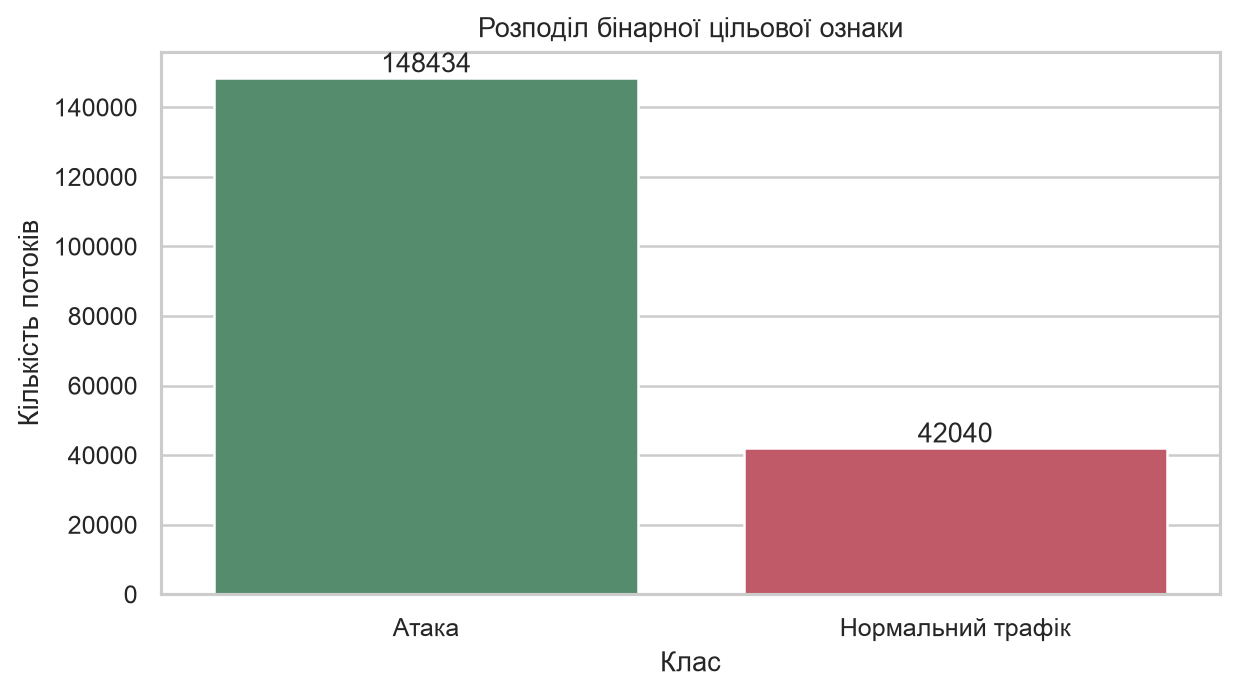

In [2]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'class_distribution.png'), width=760))

## Розподіл типів атак

У наборі представлені дев'ять категорій атак. MITM має найменше прикладів, тому в наступній роботі варто перевіряти класові метрики, а для багатокласового завдання застосовувати зважування або окремо обговорити малий обсяг MITM.

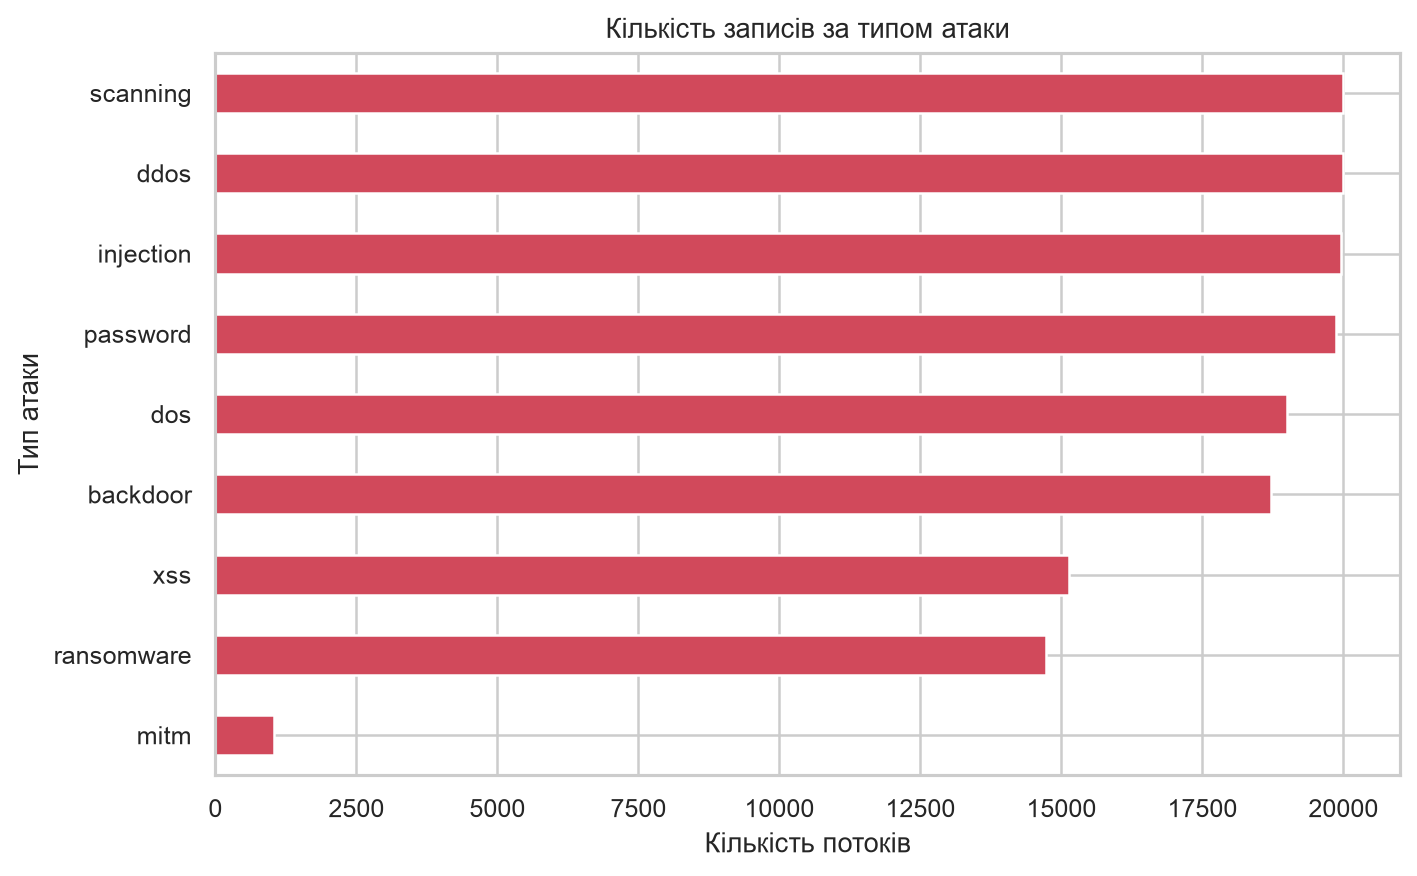

In [3]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'attack_types.png'), width=760))

## Мітки за адресами джерела

Класи розподілені нерівномірно між адресами джерела. IP-адреси не подаються моделі як ознаки; записи однієї адреси залишаються в одній частині групового розбиття, щоб зменшити витік і перевірити перенесення на невідомі джерела.

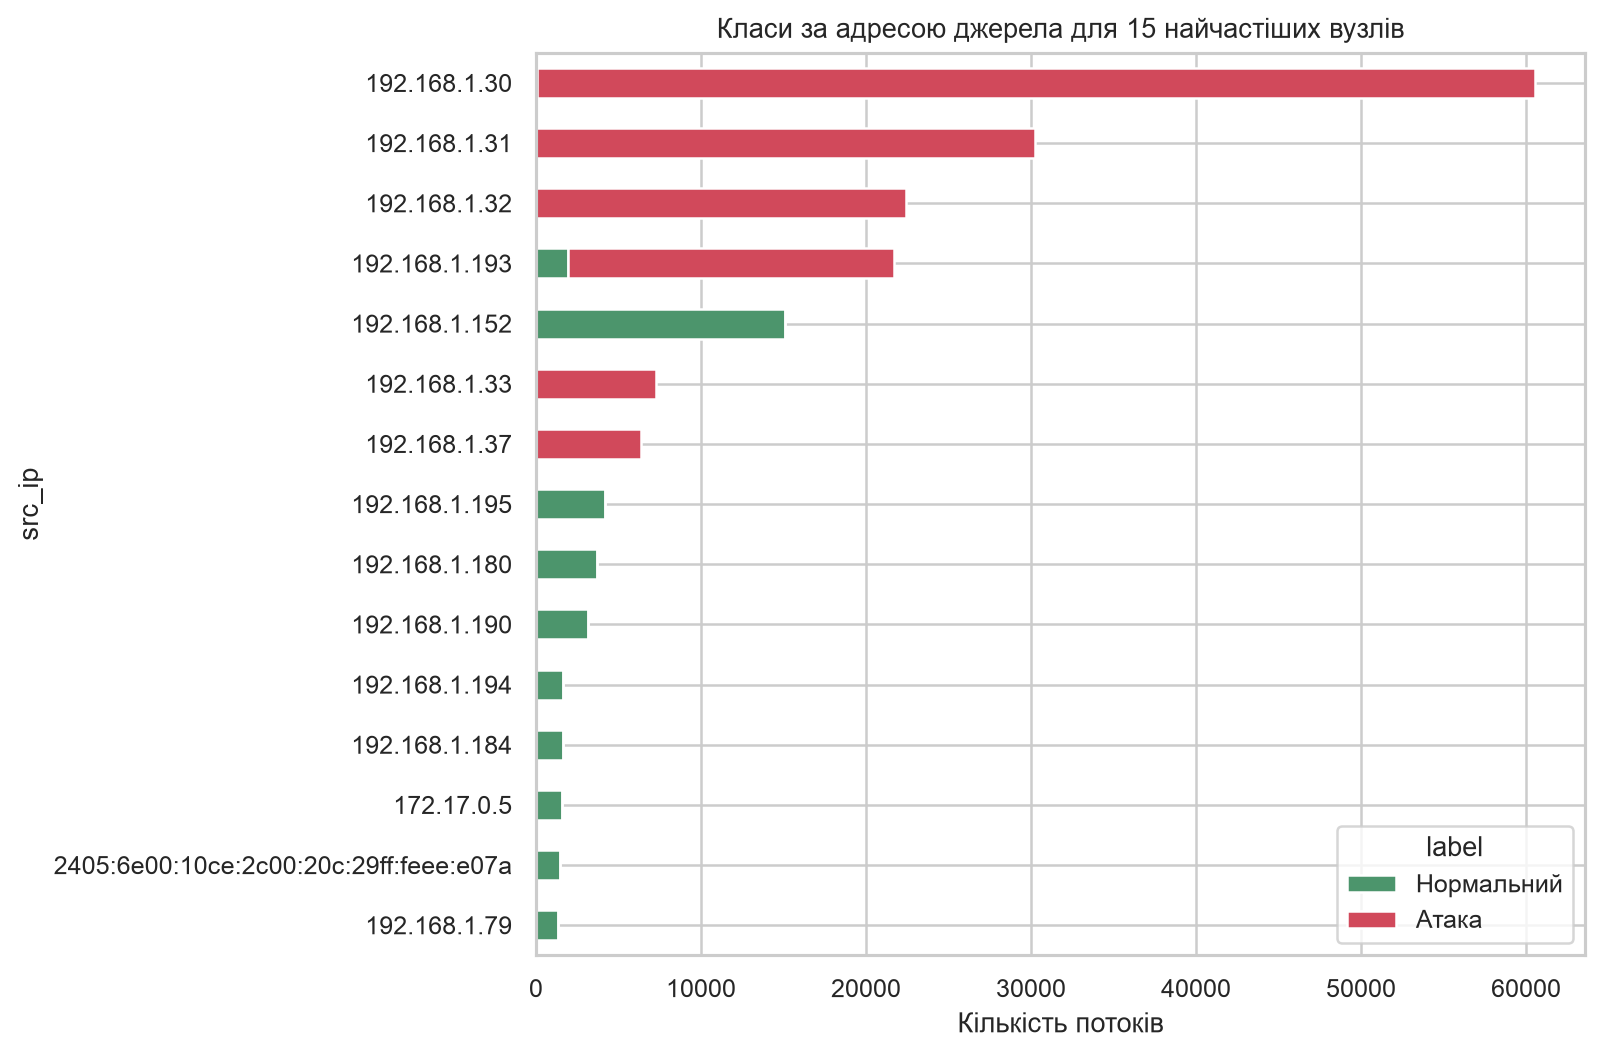

In [4]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'source_ip_grouping.png'), width=760))

## Розподіли числових ознак

Тривалість, обсяги байтів і кількість пакетів мають довгі праві хвости. Для первинної візуалізації застосовано log1p; у конвеєрі модельної підготовки числові значення очищаються від нескінченностей, а Logistic Regression масштабує ознаки.

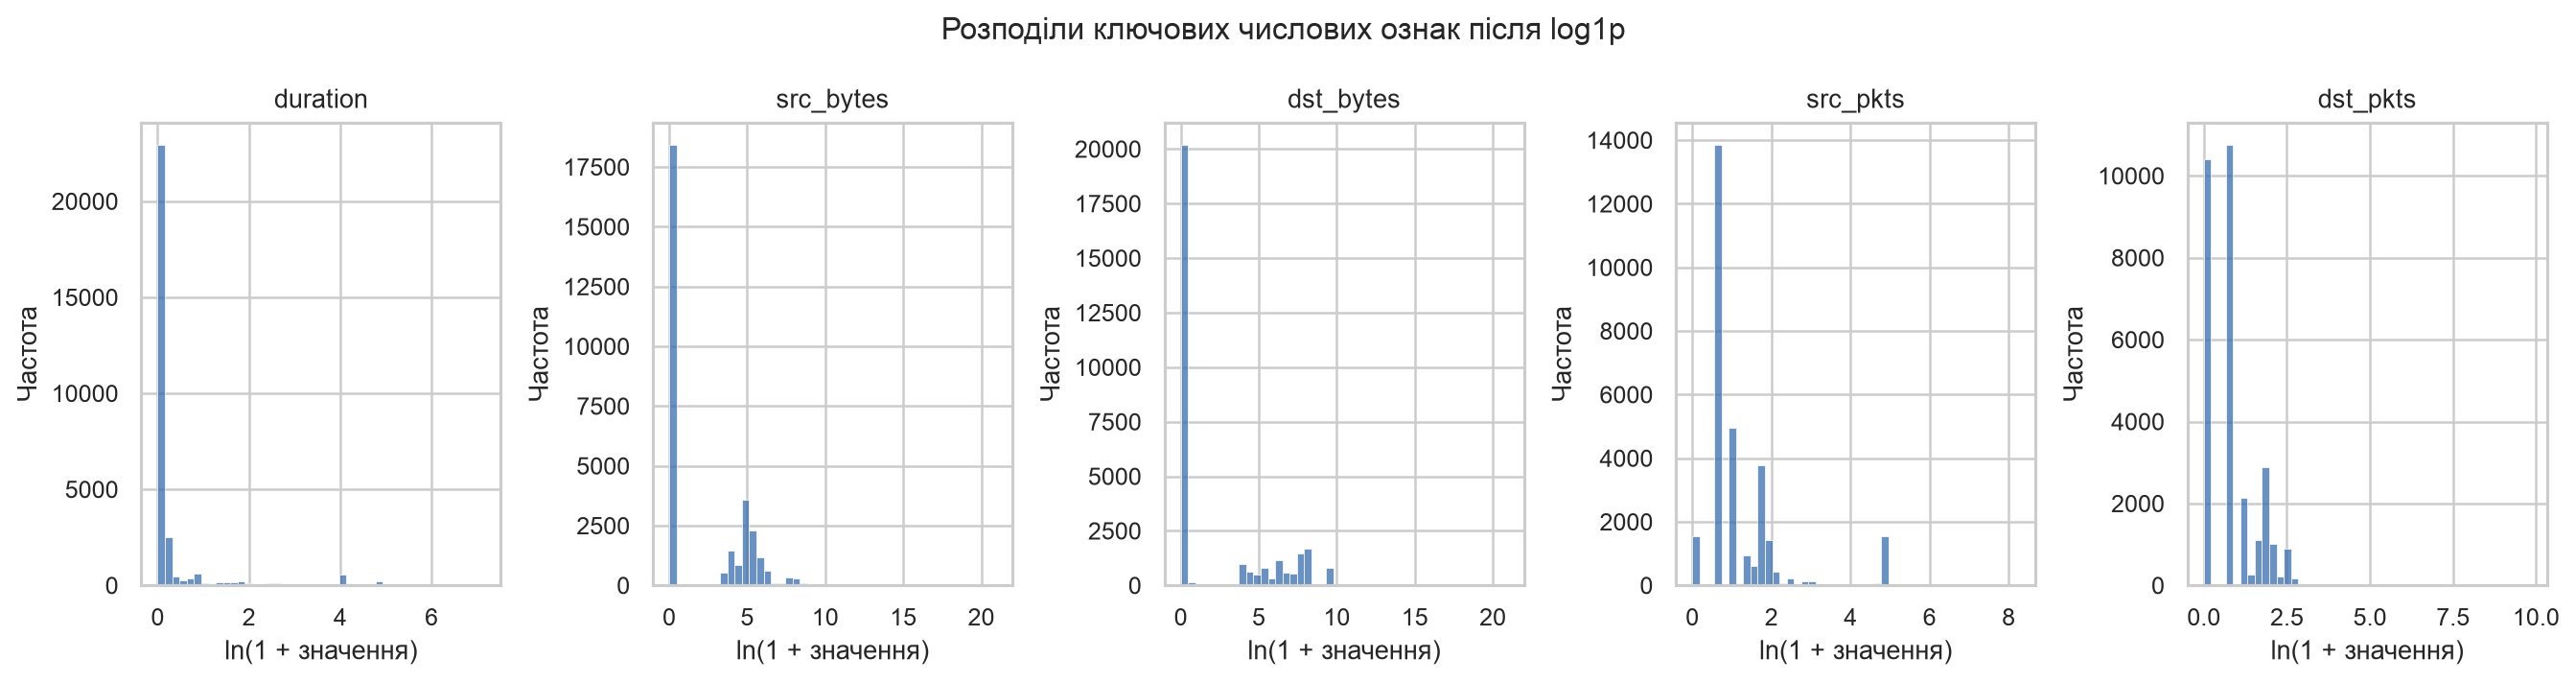

In [5]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'numeric_distributions.png'), width=760))

## Пропуски й дублікати

Пропущених значень у завантаженому файлі немає. Виявлено 20 569 точних повторів; їх видалено до розбиття, оскільки повторні однакові рядки могли б штучно полегшити оцінювання.

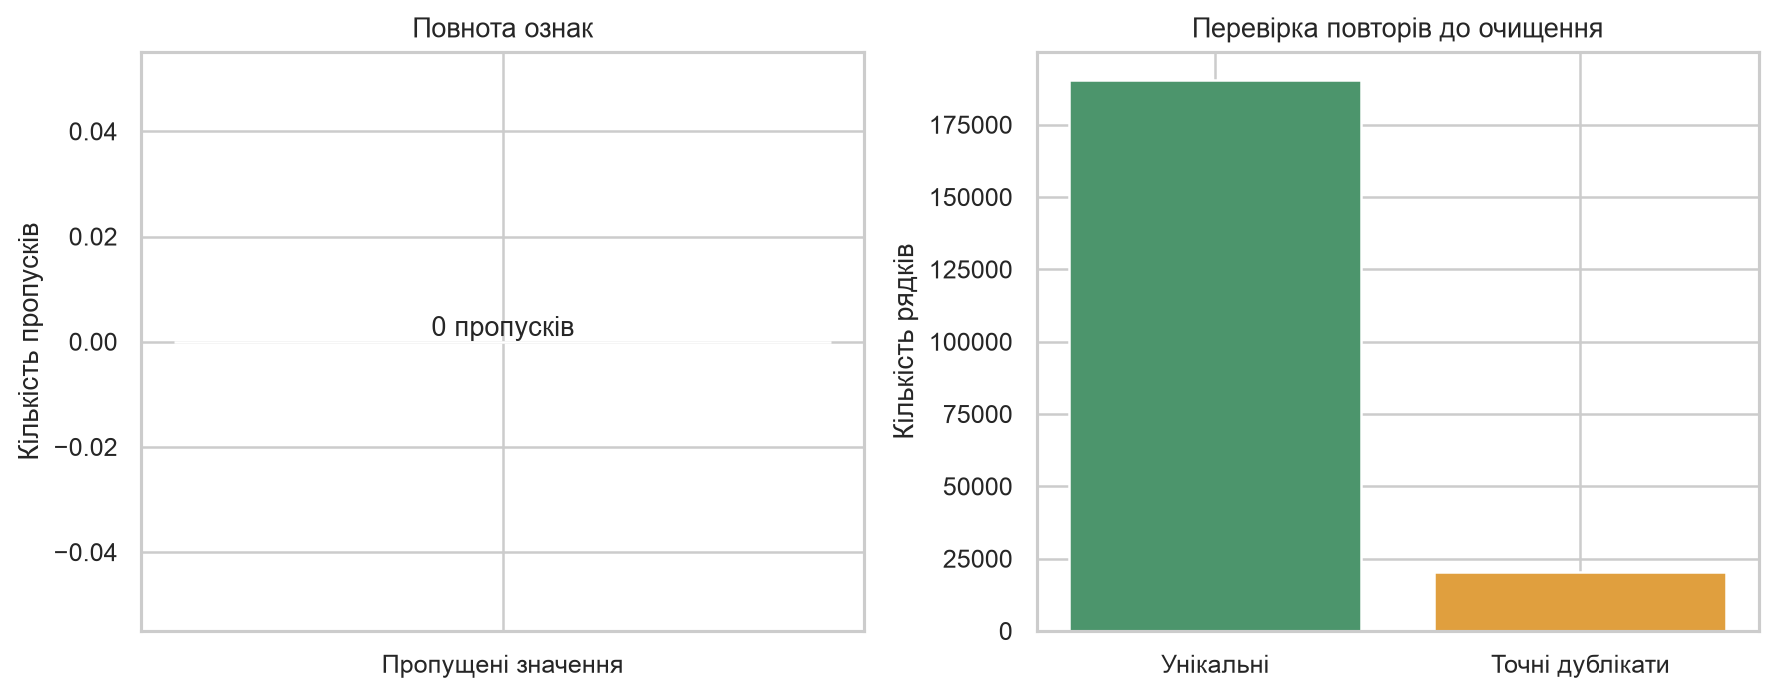

In [6]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'missing_duplicates.png'), width=760))

## Кореляції ознак

Кореляційна матриця показує залежності між обсягом переданих даних, кількістю пакетів та іншими числовими характеристиками. Для дерева корельовані ознаки не потребують масштабування, однак лінійна модель масштабує їх і використовує як простий порівняльний метод.

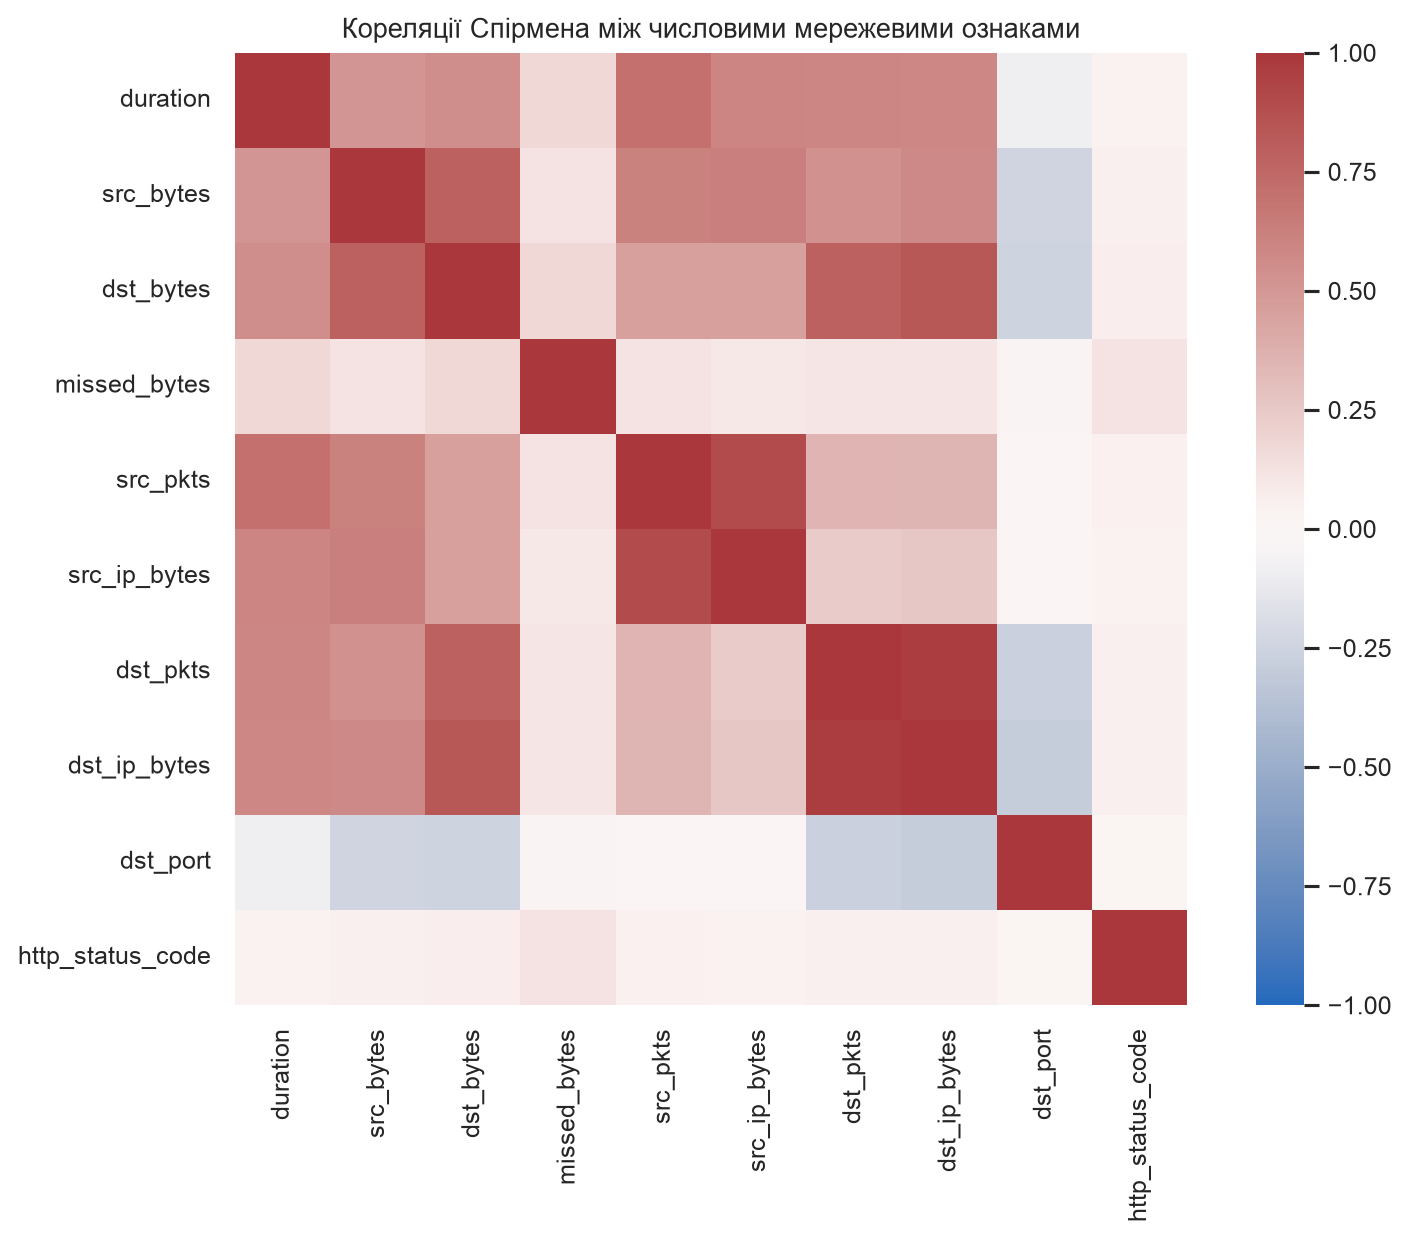

In [7]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'correlation_matrix.png'), width=760))

## Викиди за класами

Розкид мережевих показників суттєво відрізняється між класами та містить крайні значення. Викиди не видаляються автоматично: вони можуть бути характерною ознакою DoS/DDoS, тому в майбутній моделі потрібні перевірка стійкості та контроль впливу екстремальних значень.

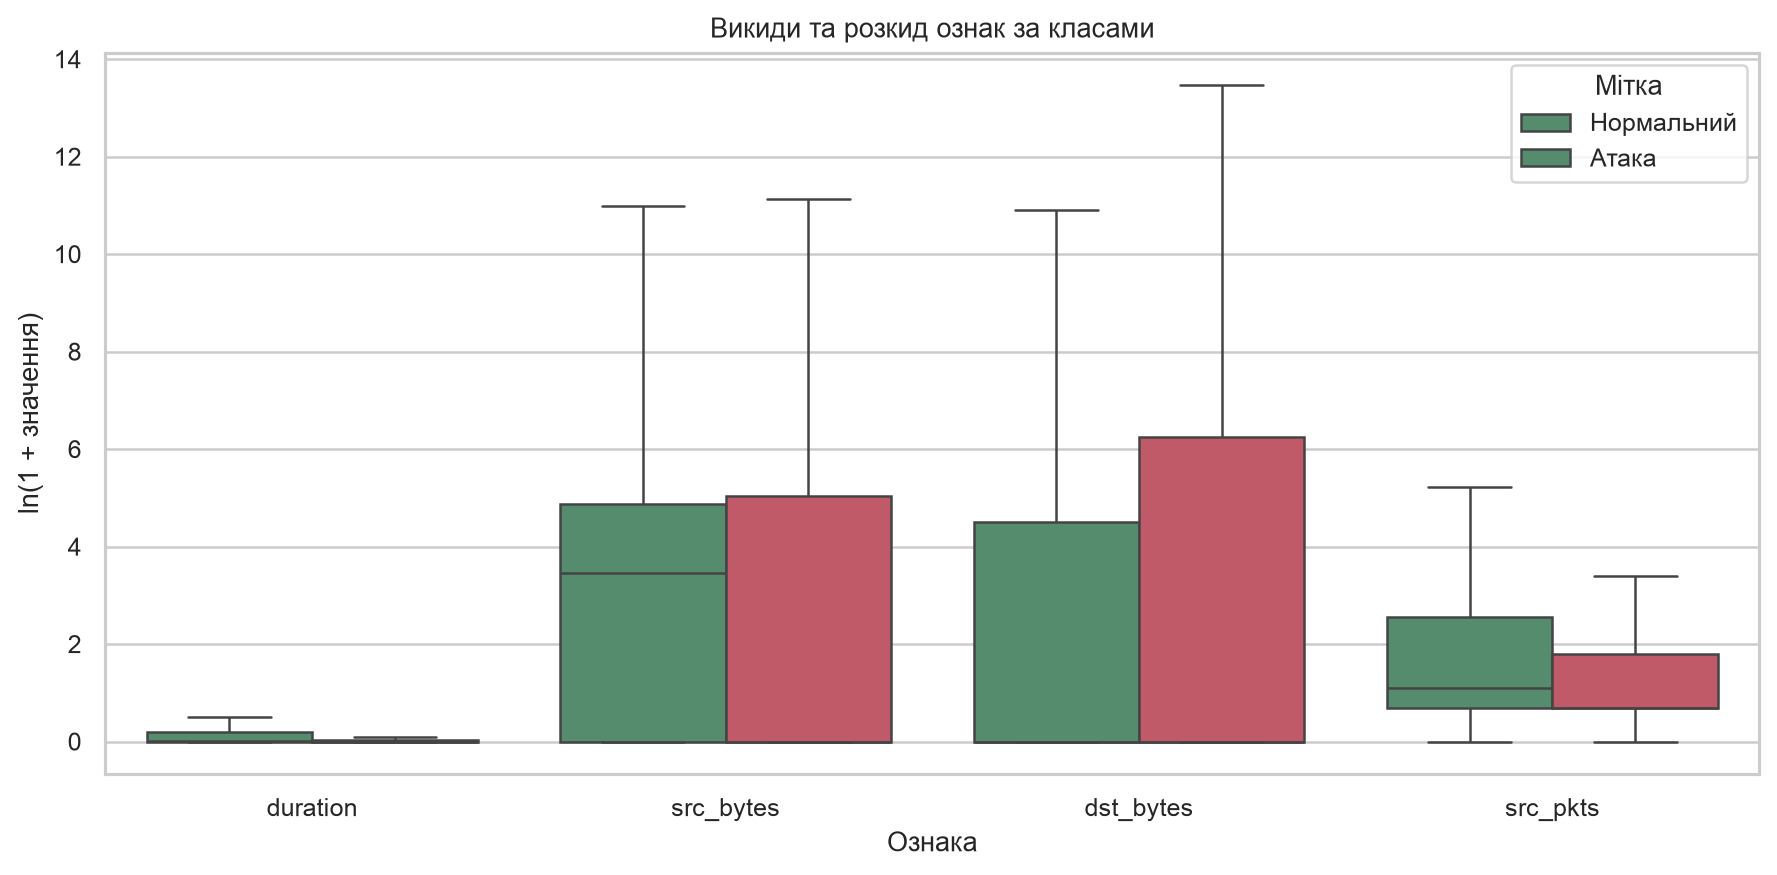

In [8]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'outlier_boxplots.png'), width=760))

## Порівняння методів

На груповій відкладеній вибірці Random Forest має найвище F1 атак; Logistic Regression дає вищий recall, але нижчий precision. Сигнатурні правила й Isolation Forest у цій конфігурації пропускають значну частину атак, що підтверджує доцільність контрольованої моделі як основи системи.

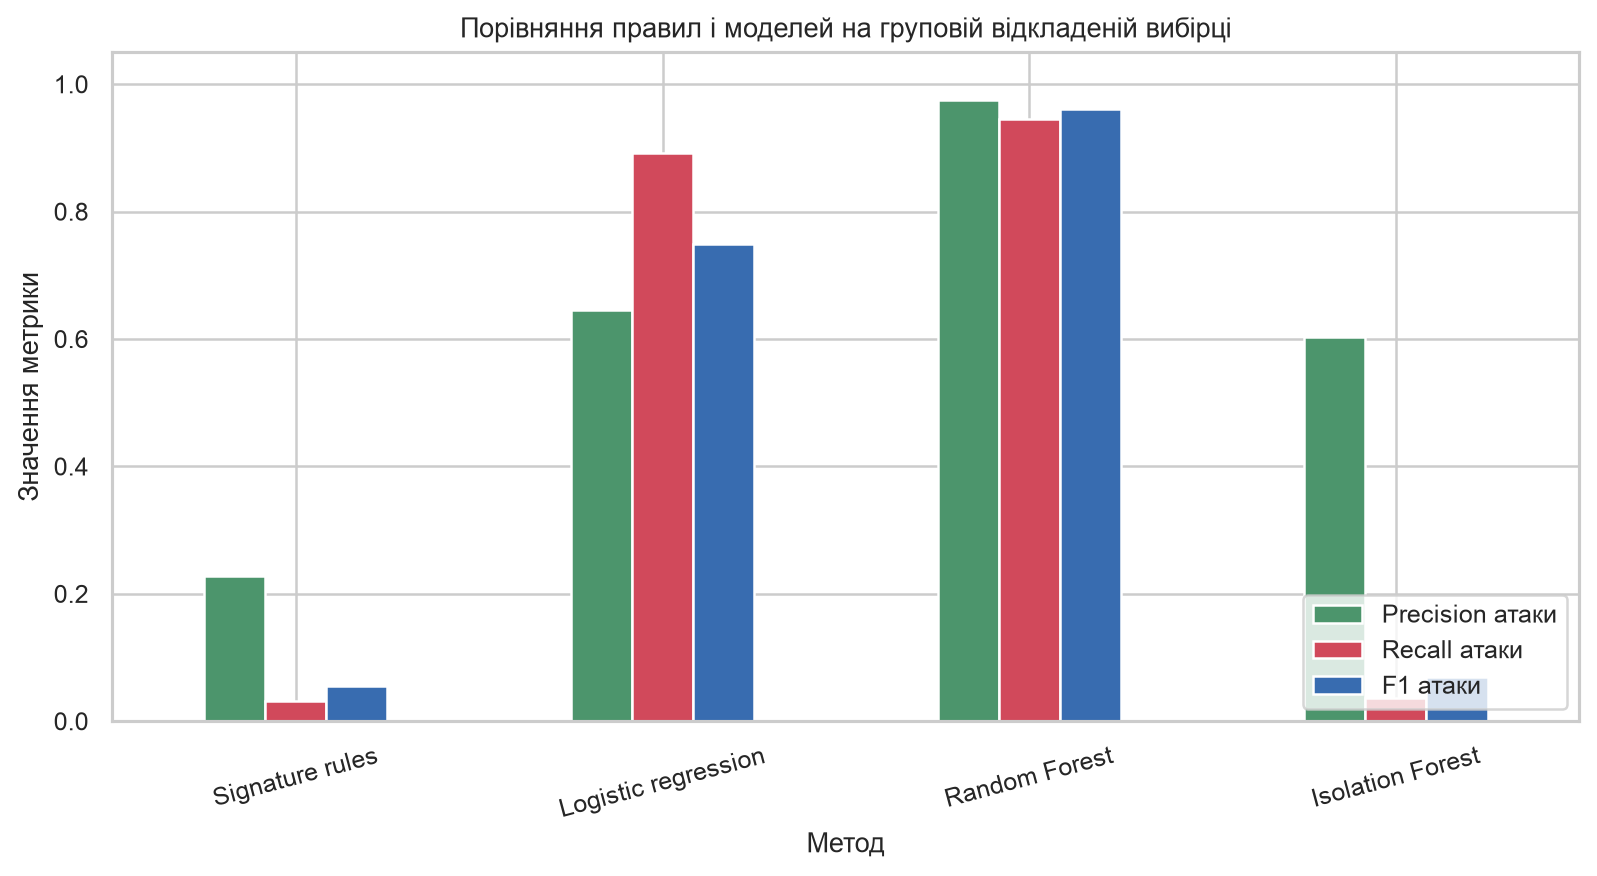

In [9]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'model_comparison.png'), width=760))

## Матриця помилок Random Forest

Матриця помилок показує окремо хибні тривоги й пропущені атаки, а не приховує їх загальним показником accuracy. Перед автоматичним карантином у наступних роботах рішення моделі має містити впевненість і журналюватися, а звільнення пристрою залишається ручним.

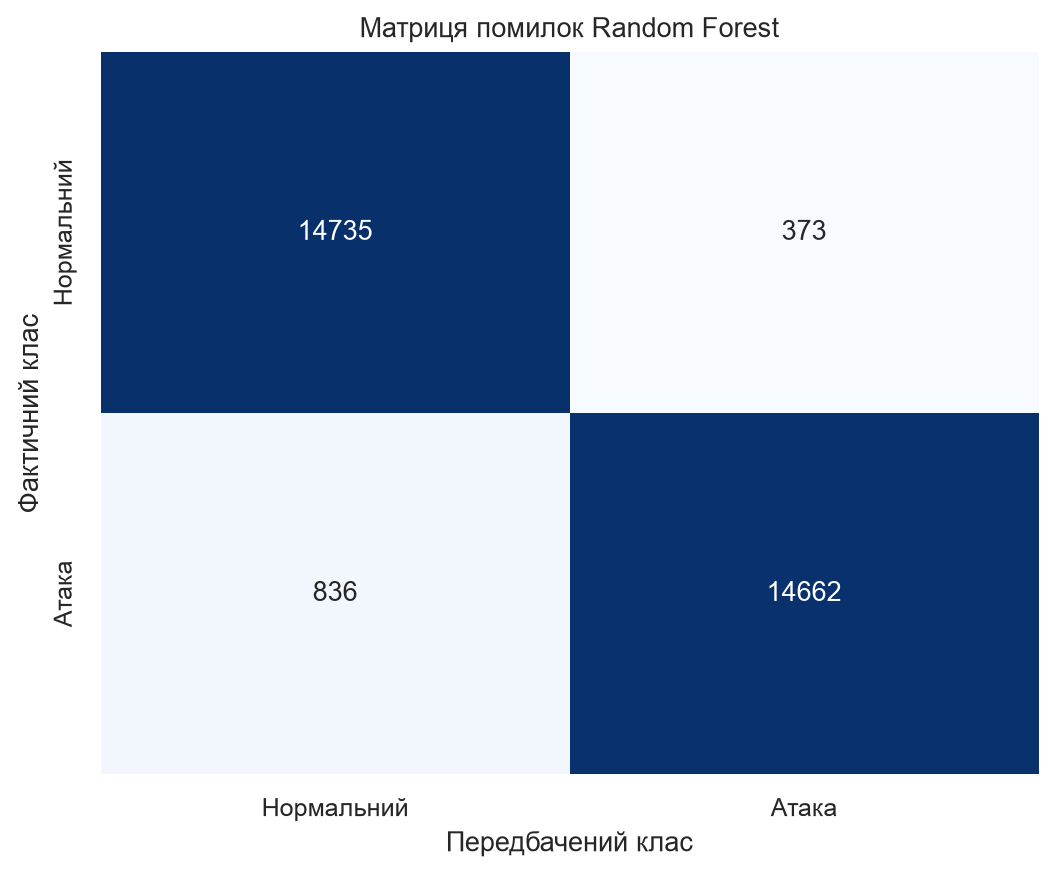

In [10]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'rf_confusion_matrix.png'), width=760))

## Важливість ознак Random Forest

Найважливішими стали обсяги байтів і пакетні показники. Це відповідає мережевому характеру ознак, але importance Gini не доводить причинний зв'язок; у ЛР 3 результати слід перевірити на відкладених даних і доповнити аналізом помилок.

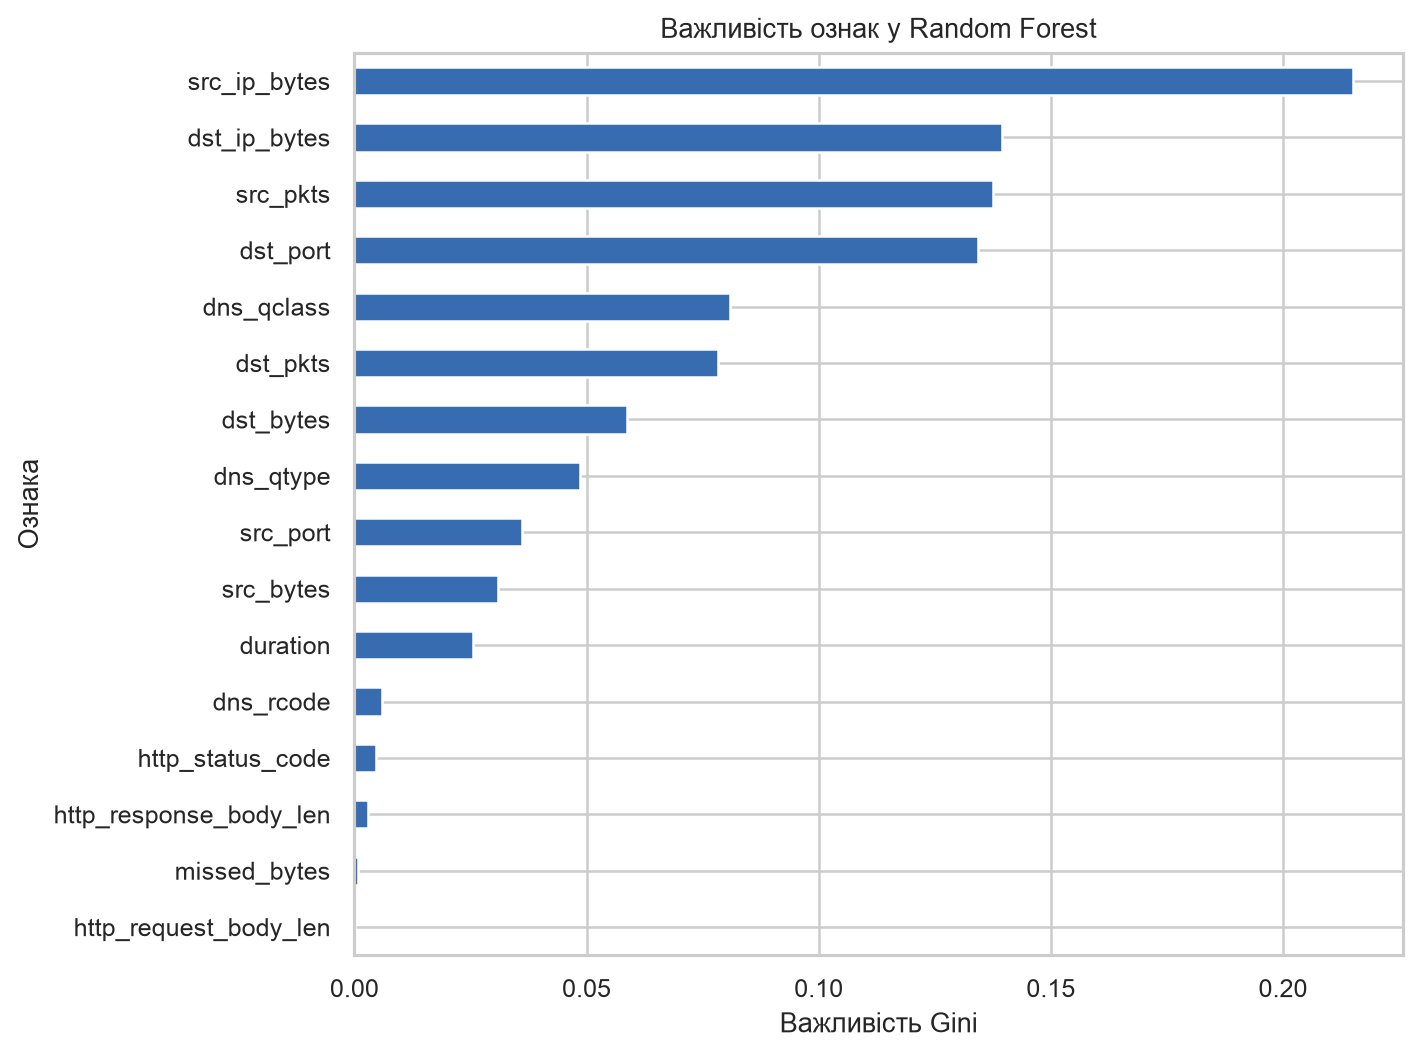

In [11]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'images' / 'feature_importance.png'), width=760))

## Початкове порівняння методів

Розбиття виконано через StratifiedGroupKFold за `src_ip`: усі записи одного джерела належать лише train або test. Гіперпараметри на цьому етапі не підбираються; значення є попереднім базовим результатом для подальшої перевірки у ЛР 3.

In [12]:
metrics = pd.DataFrame(summary['metrics']).T
metrics[['accuracy','precision_attack','recall_attack','f1_attack','pr_auc','roc_auc']].round(4)

,accuracy,precision_attack,recall_attack,f1_attack,pr_auc,roc_auc
Signature rules,0.4560,0.2283,0.0312,0.0549,0.4977,0.4615
Logistic regression,0.6982,0.6463,0.8925,0.7497,0.7973,0.8641
Random Forest,0.9605,0.9752,0.9461,0.9604,0.9702,0.9558
Isolation Forest,0.5000,0.6027,0.0371,0.0699,0.5356,0.4153


## Попередній висновок

Random Forest на відкладених джерелах дає найкращий баланс precision і recall у цьому експерименті. Isolation Forest та прості сигнатури не виявляють достатньої частки атак, а логістична регресія залишається простим контрольним методом. Ці числа є попередніми: фінальне порівняння, підбір параметрів, крос-валідація, оцінка хибних тривог і перевірка на зміні розподілу виконуються в лабораторній роботі № 3.